#Import

In [1]:
from PIL import Image  # Import the Image module from Pillow
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

#MNIST classification using CNN model

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 63s 40ms/step - accuracy: 0.9465 - loss: 0.1754 - val_accuracy: 0.9818 - val_loss: 0.0587
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 34ms/step - accuracy: 0.9834 - loss: 0.0537 - val_accuracy: 0.9840 - val_loss: 0.0514
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 48s 32ms/step - accuracy: 0.9887 - loss: 0.0358 - val_accuracy: 0.9885 - val_loss: 0.0401
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 48s 32ms/step - accuracy: 0.9916 - loss: 0.0263 - val_accuracy: 0.9875 - val_loss: 0.0418
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 81s 31ms/step - accuracy: 0.9932 - loss: 0.0205 - val_accuracy: 0.9890 - val_loss: 0.0392
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


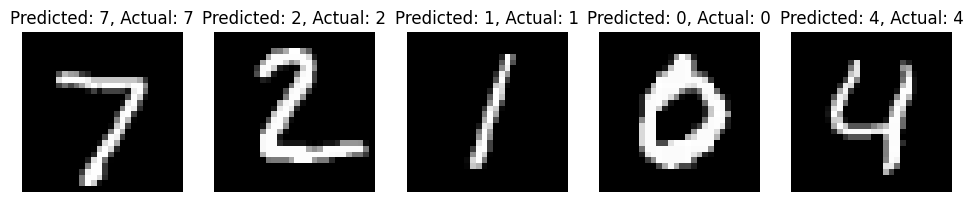

In [1]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load the MNIST Dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocess the Data
x_train = x_train.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

# Build a Simple CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0-9
])

# Compile the Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the Model
model.fit(x_train, y_train, epochs=5, validation_split=0.2)

# Make Predictions on Test Set
predictions = model.predict(x_test)

# Display Sample Predictions
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {tf.argmax(predictions[i]).numpy()}, Actual: {y_test[i]}")
    plt.axis('off')
plt.show()


#Object Detection

In [3]:
# Set up the environment
!git clone https://github.com/ultralytics/yolov5  # Clone the YOLOv5 repo
%cd yolov5
!pip install -r requirements.txt  # Install requirements

# Import libraries
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load a pre-trained YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')  # Load YOLOv5s model (small)


Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (331/331), done.
remote: Compressing objects: 100% (194/194), done.
remote: Total 18770 (delta 270), reused 137 (delta 137), pack-reused 18439 (from 5)
Receiving objects: 100% (18770/18770), 17.80 MiB | 25.85 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 640.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 7.5 MB/s eta 0:00:00
The repository ultralytics_yolov5 does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to /root/.cache/torch/hub/m

100%|██████████| 14.1M/14.1M [00:00<00:00, 32.6MB/s]


Fusing layers... 


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [4]:
!pip install requests


In [5]:
import requests

# Define the URL of the image
url = 'https://github.com/ultralytics/yolov5/releases/download/v1.0/zidane.jpg'

# Send a GET request to the URL
response = requests.get(url)

# Open a file in binary write mode
with open('zidane.jpg', 'wb') as f:
    f.write(response.content)

print("Image downloaded successfully!")


Image downloaded successfully!


YOLOv5 🚀 2026-10-15 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


Adding AutoShape... 


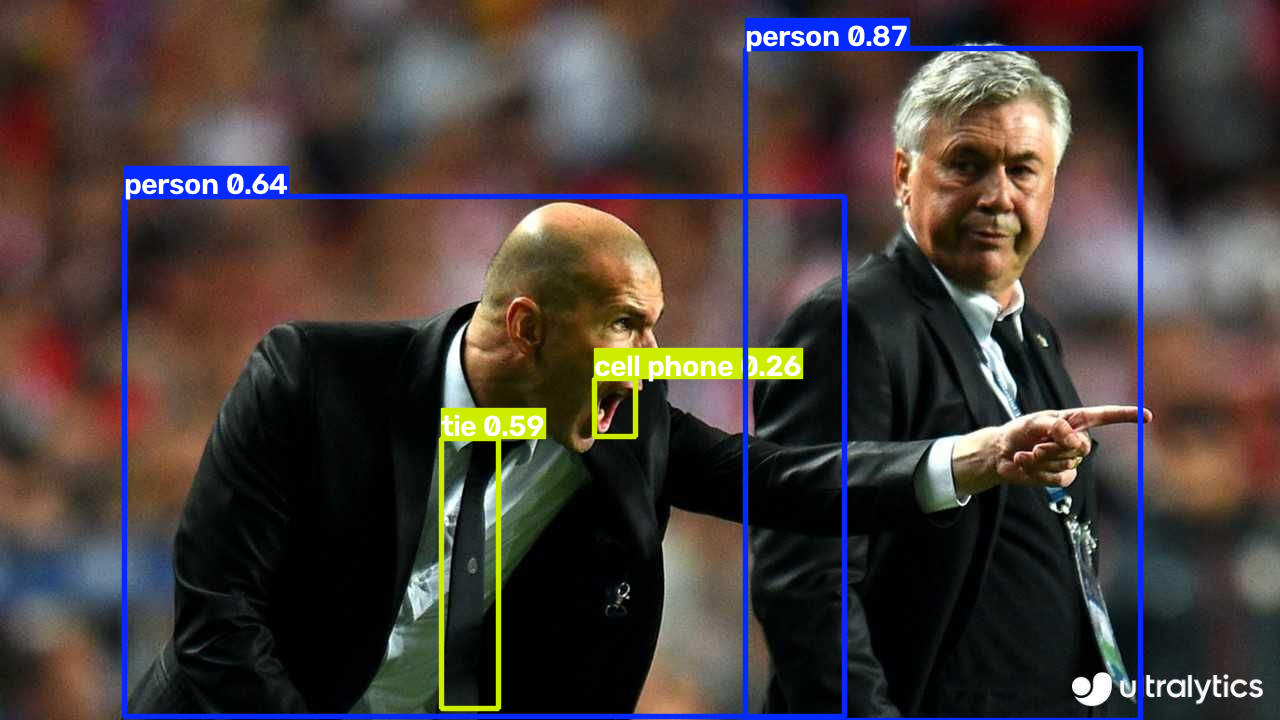

In [6]:
import torch

# Load the YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')

# Load the image
img = 'zidane.jpg'  # path to your image

# Perform inference
results = model(img)

# Show results
results.show()  # This will display the image with detections


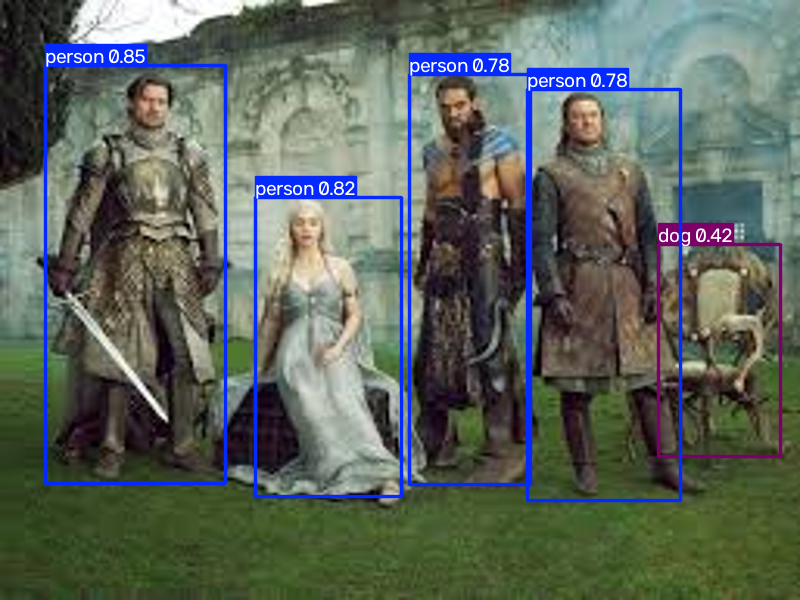

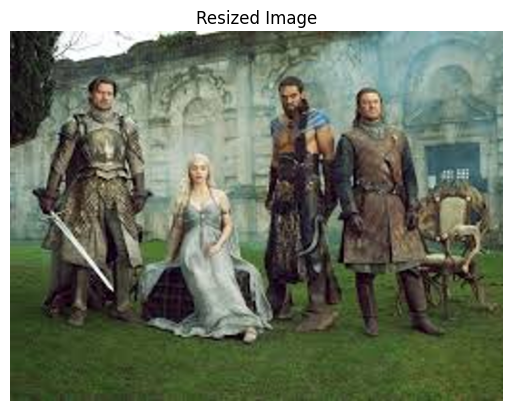

In [7]:
img_path = '/content/game of thrones.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


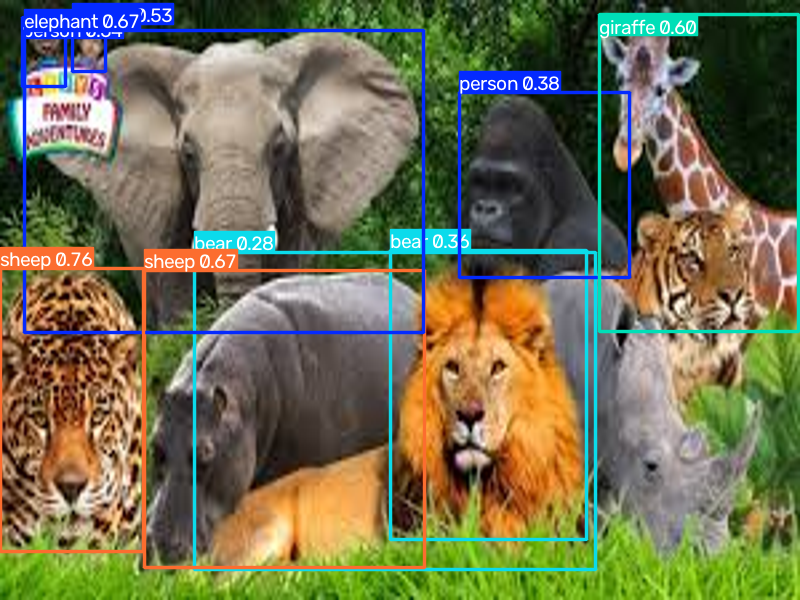

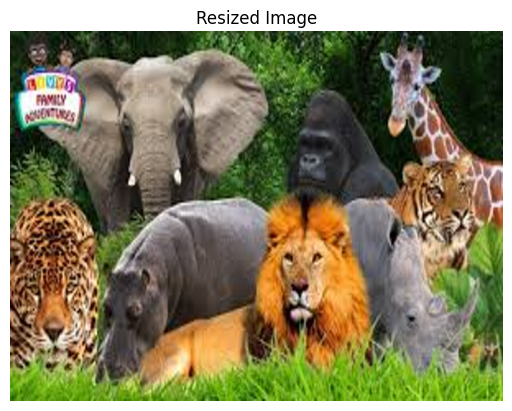

In [8]:
img_path = '/content/animals.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


#Segmentation

In [9]:
!pip install tensorflow tensorflow-datasets matplotlib numpy


#HomeWork2

Run this cell first to load the required dataset

In [3]:
from sklearn.datasets import fetch_openml
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist['data'], mnist['target']

# Preprocess the Data
X = X / 255.0  # Normalize pixel values to [0, 1]
y = y.astype(np.uint8)  # Convert labels to integers

#  Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

##Part1 : In this section, we want to classify the MNIST dataset using Random Forest, Logistic Regression, and Neural Networks. We will print the accuracy for each model. The code for Random Forest will serve as an example, and you should complete the code for Logistic Regression and Neural Networks accordingly.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Train Different Classifiers

# 1. Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 2. Logistic Regression
# Create and fit the Logistic Regression model
logistic_classifier = LogisticRegression(max_iter=1000, random_state=42)
logistic_classifier.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_classifier.predict(X_test)
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print(accuracy_logistic)

0.9202142857142858


In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# 3. MLP (Neural Network)
# Create and fit the MLP (Neural Network) model
mlp = MLPClassifier(random_state=42, max_iter=100)
mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
print(f"MLP Neural Network Accuracy: {accuracy_mlp:.4f}")

MLP Neural Network Accuracy: 0.9755


In [13]:
print("MNIST Classification Results")
print(f"Random Forest: {accuracy_rf * 100:.2f}%")
print(f"Logistic Regression: {accuracy_logistic * 100:.2f}%")
print(f"MLP Neural Network: {accuracy_mlp * 100:.2f}%")

MNIST Classification Results
Random Forest: 96.75%
Logistic Regression: 92.02%
MLP Neural Network: 97.55%


In [23]:
# Step 6: Print Accuracy Results
print(f'Logistic Regression Accuracy: {accuracy_logistic * 100:.2f}%')
print(f'Random Forest Accuracy: {accuracy_rf * 100:.2f}%')
print(f'MLP Accuracy: {accuracy_mlp * 100:.2f}%')

Logistic Regression Accuracy: 92.03%
Random Forest Accuracy: 96.75%
MLP Accuracy: 97.55%


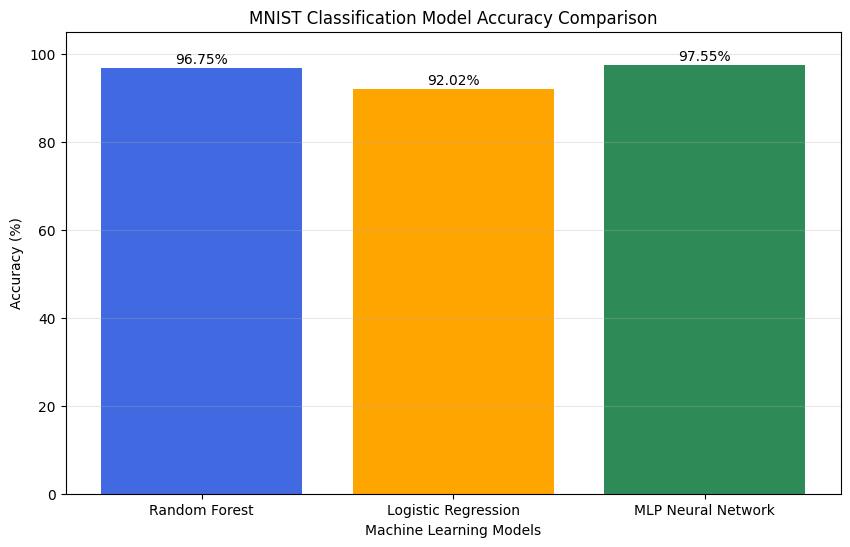

In [14]:
import matplotlib.pyplot as plt

models = ['Random Forest', 'Logistic Regression', 'MLP Neural Network']
accuracies = [
    accuracy_rf * 100,
    accuracy_logistic * 100,
    accuracy_mlp * 100
]

plt.figure(figsize=(10, 6))
bars = plt.bar(models, accuracies,
               color=['royalblue', 'orange', 'seagreen'])

plt.title('MNIST Classification Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        score + 1,
        f'{score:.2f}%',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.show()

### MNIST Classification Results and Discussion

Three machine-learning models were trained and evaluated using the MNIST handwritten-digit dataset: Random Forest, Logistic Regression, and a Multilayer Perceptron (MLP) Neural Network. The MLP Neural Network achieved the highest classification accuracy at 97.55%, followed by Random Forest at 96.75% and Logistic Regression at 92.02%. These results demonstrate that all three models can recognize handwritten digits with relatively high accuracy. However, the MLP Neural Network performed best on the test dataset, suggesting that its ability to learn more complex patterns was beneficial for this classification task.

## Part2: take a photo of yourself, upload it to the jupyter notebook and detect your face using Yolo model

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5 🚀 2026-10-27 Python-3.13.16 torch-2.11.0+cpu CPU



100%|██████████| 14.1M/14.1M [00:00<00:00, 111MB/s] 

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


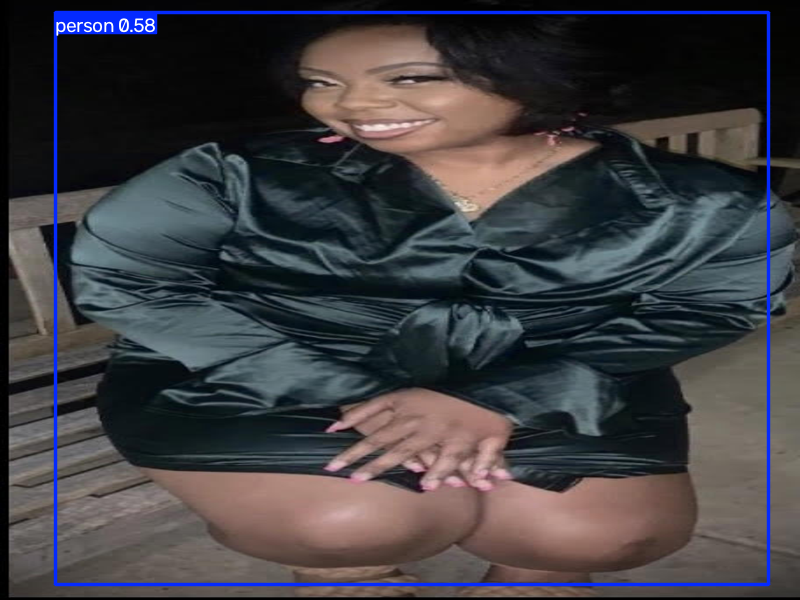

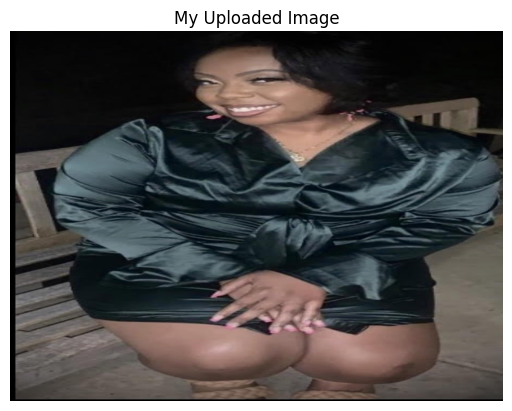

In [18]:
# Install ultralytics package directly
!pip install -q ultralytics

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

# Reload YOLOv5 specifically to avoid conflict with the Keras MNIST 'model'
yolo_model = torch.hub.load('ultralytics/yolov5', 'yolov5s')

# 1. Change this path to match your uploaded image file name
img_path = '/content/Picture of Malia.jpg'
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a NumPy array
img_array = np.array(resized_image)

# Perform face/object detection using YOLOv5
results = yolo_model(img_array)

# Show results with bounding boxes
results.show()

# Visualize the uploaded image
plt.imshow(resized_image)
plt.axis('off')
plt.title('My Uploaded Image')
plt.show()

### YOLO Object Detection Results and Discussion

The YOLOv5 object detection model was used to analyze an uploaded photograph containing a person. The model successfully identified the person and generated a bounding box around the detected subject with a confidence score of 0.58 (58%). This demonstrates YOLO's ability to locate and classify objects within an image. Although the model successfully detected the person, it did not specifically identify the face because the pretrained YOLOv5 model is designed for general object detection rather than dedicated facial detection. Overall, the results demonstrate how deep-learning-based computer vision can be used to identify objects in digital images.